# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
import pandas as pd

df = pd.read_csv(r"C:\Users\fedaa\Downloads\Lab_11_QnA_Dataset.csv")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(
            len(tokenizer.word_index) + 1, 16,
            padding_idx=0
        )
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x_, _ = self.rnn(self.emb(x))

        scores = self.att(x_).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)
        weights = torch.softmax(scores, dim=1)

        context = (x_ * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
model = RNN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    model.train()
    optimizer.zero_grad()

    prediction, weights = model(X)
    loss = nn.functional.cross_entropy(prediction, y)

    loss.backward()
    optimizer.step()

print("Training finished!")
print("Final loss:", loss.item())


Training finished!
Final loss: 0.053743164986371994


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

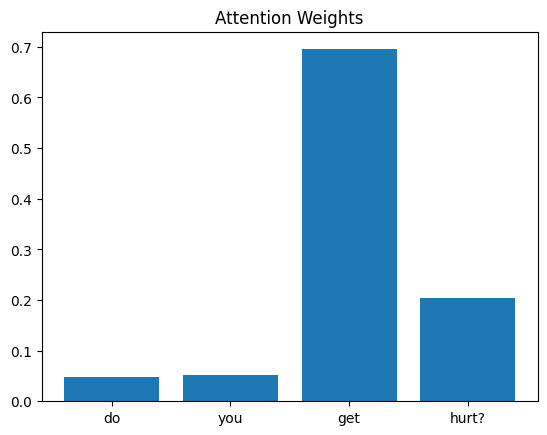

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

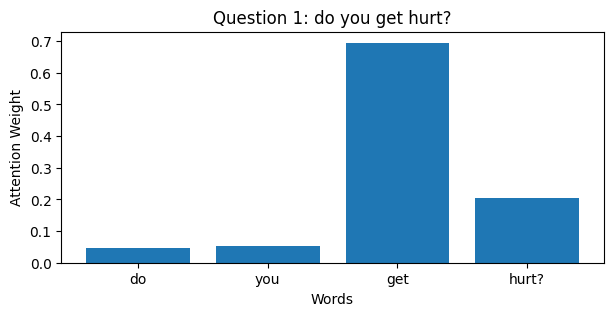

Question: do you get hurt?
Highest attention word: get
Highest attention weight: 0.6952
----------------------------------------


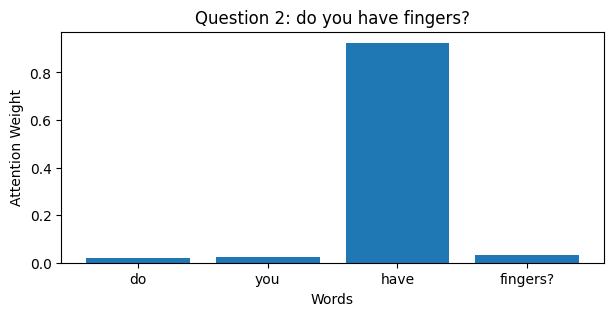

Question: do you have fingers?
Highest attention word: have
Highest attention weight: 0.9252
----------------------------------------


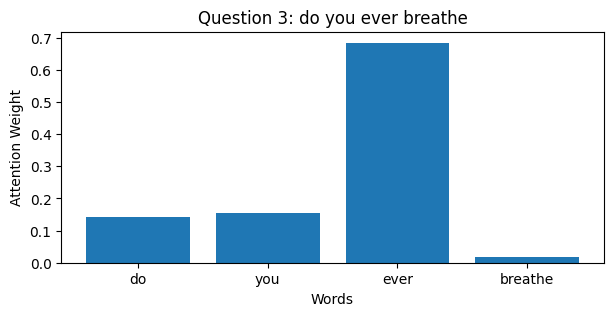

Question: do you ever breathe
Highest attention word: ever
Highest attention weight: 0.6841
----------------------------------------


In [7]:
model.eval()

for i in [0, 1, 2]:
    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention = weights[0, :len(words)].tolist()

    plt.figure(figsize=(7, 3))
    plt.bar(words, attention)
    plt.title(f"Question {i+1}: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    highest = words[attention.index(max(attention))]

    print("Question:", question)
    print("Highest attention word:", highest)
    print("Highest attention weight:", round(max(attention), 4))
    print("-" * 40)


In [8]:
model.eval()

for i in [0, 1, 2]:
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    print("Question:", df["question"].iloc[i])
    print("Attention sum:", round(weights[0].sum().item(), 4))
    print("-" * 30)


Question: do you get hurt?
Attention sum: 1.0
------------------------------
Question: do you have fingers?
Attention sum: 1.0
------------------------------
Question: do you ever breathe
Attention sum: 1.0
------------------------------


In [9]:
for i in [0, 1, 2]:
    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        _, weights = model(X[i:i+1])

    attention = weights[0, :len(words)]
    highest = attention.argmax().item()

    print("Question:", question)
    print("Highest word:", words[highest])
    print("Weight:", round(attention[highest].item(), 4))
    print("-------------------")


Question: do you get hurt?
Highest word: get
Weight: 0.6952
-------------------
Question: do you have fingers?
Highest word: have
Weight: 0.9252
-------------------
Question: do you ever breathe
Highest word: ever
Weight: 0.6841
-------------------


Task 1 – Observations

The highest attention words were "get" (0.6952), "have" (0.9252), and "ever" (0.6841).

These words are related to the questions, but they are not always the most important words for understanding the meaning. For example, in "Do you get hurt?", the model focused more on "get" than "hurt". Similarly, in "Do you have fingers?", the model focused on "have" instead of "fingers".

This shows that attention weights reflect what the model learned during training, and the highest attention words are not always the most meaningful words to humans.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

In [11]:
for i in range(20):
    print(i, ":", df["question"].iloc[i])


0 : do you get hurt?
1 : do you have fingers?
2 : do you ever breathe
3 : do you masticate?
4 : can you throw up?
5 : do you get tired?
6 : can you crawl?
7 : can you cry?
8 : do you dream
9 : do you ever pee?
10 : do you ever get hurt?
11 : can you breathe
12 : can you masticate?
13 : can you burp?
14 : are you old?
15 : are we the same age?
16 : how long have you been alive?
17 : are you a teenager?
18 : what's your birthday?
19 : which of us is younger?


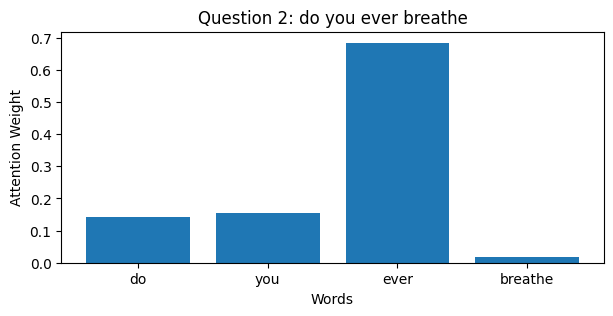

Question: do you ever breathe
Highest attention word: ever
Highest weight: 0.6841
----------------------------------------


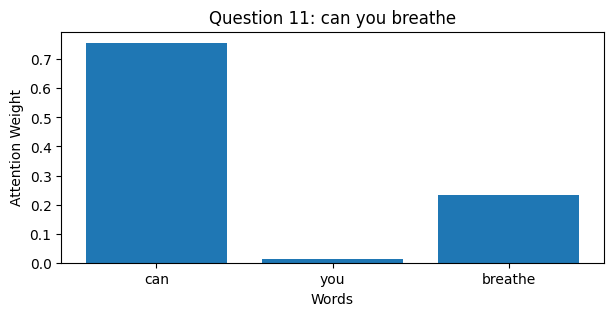

Question: can you breathe
Highest attention word: can
Highest weight: 0.7569
----------------------------------------


In [12]:

model.eval()

for i in [2, 11]:
    question = df["question"].iloc[i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention = weights[0, :len(words)].tolist()

    plt.figure(figsize=(7, 3))
    plt.bar(words, attention)
    plt.title(f"Question {i}: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    highest = words[attention.index(max(attention))]

    print("Question:", question)
    print("Highest attention word:", highest)
    print("Highest weight:", round(max(attention), 4))
    print("-" * 40)


### Task 2 – Comparison and Observations

The two selected questions were "Do you ever breathe?" and "Can you breathe?". Both questions have similar meanings but different wording.

For the first question, the model gave the highest attention weight to "ever" (0.6841). For the second question, it focused on "can" (0.7569).

The model focused on different words even though the questions have similar meanings. This suggests that attention weights depend on the wording and context of each question, as well as the patterns learned during training. Therefore, similar questions do not necessarily receive the same attention distribution.